In [1]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"muhammetfatihetintas","key":"61dcff2dfcef6dac52a665111adf41f7"}'}

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("antobenedetti/animals")

print("Path to dataset files:", path)

!unzip /kaggle/input/animals

Path to dataset files: /kaggle/input/animals
unzip:  cannot find or open /kaggle/input/animals, /kaggle/input/animals.zip or /kaggle/input/animals.ZIP.


In [5]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import os

In [6]:
base_dir = '/kaggle/input/animals/animals'
train_dir = os.path.join(base_dir, 'train')
test_dir = os.path.join(base_dir, 'val')
for root , dirs, files in os.walk(base_dir):
  print(root, ':', len(files))

img_size = (128, 128)
batch_size = 16

train_datagen = ImageDataGenerator(
    rescale=0./255,
    validation_split=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training'
)

validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation'
)


/kaggle/input/animals/animals : 0
/kaggle/input/animals/animals/inf : 5
/kaggle/input/animals/animals/val : 0
/kaggle/input/animals/animals/val/horse : 300
/kaggle/input/animals/animals/val/lion : 298
/kaggle/input/animals/animals/val/dog : 300
/kaggle/input/animals/animals/val/elephant : 299
/kaggle/input/animals/animals/val/cat : 300
/kaggle/input/animals/animals/train : 0
/kaggle/input/animals/animals/train/horse : 2705
/kaggle/input/animals/animals/train/lion : 2675
/kaggle/input/animals/animals/train/dog : 2627
/kaggle/input/animals/animals/train/elephant : 2730
/kaggle/input/animals/animals/train/cat : 2737
Found 10780 images belonging to 5 classes.
Found 2694 images belonging to 5 classes.


In [7]:
vgg_base = VGG16(weights='imagenet', include_top=False, input_shape=(128, 128, 3))

for layer in vgg_base.layers:
  layer.trainable = False

model = models.Sequential()
model.add(vgg_base)
model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(5, activation='softmax'))

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [9]:
history = model.fit(
    train_generator,
    epochs=30,
    validation_data=validation_generator
)


Epoch 1/30
674/674 ━━━━━━━━━━━━━━━━━━━━ 115s 171ms/step - accuracy: 0.8259 - loss: 0.7712 - val_accuracy: 0.8749 - val_loss: 0.5553
Epoch 2/30
674/674 ━━━━━━━━━━━━━━━━━━━━ 84s 125ms/step - accuracy: 0.8447 - loss: 0.6315 - val_accuracy: 0.8924 - val_loss: 0.3970
Epoch 3/30
674/674 ━━━━━━━━━━━━━━━━━━━━ 85s 125ms/step - accuracy: 0.8675 - loss: 0.4834 - val_accuracy: 0.9235 - val_loss: 0.2966
Epoch 4/30
674/674 ━━━━━━━━━━━━━━━━━━━━ 84s 125ms/step - accuracy: 0.8787 - loss: 0.4320 - val_accuracy: 0.9157 - val_loss: 0.2554
Epoch 5/30
674/674 ━━━━━━━━━━━━━━━━━━━━ 84s 124ms/step - accuracy: 0.8812 - loss: 0.4206 - val_accuracy: 0.9094 - val_loss: 0.2873
Epoch 6/30
674/674 ━━━━━━━━━━━━━━━━━━━━ 85s 126ms/step - accuracy: 0.8827 - loss: 0.3888 - val_accuracy: 0.9261 - val_loss: 0.2314
Epoch 7/30
674/674 ━━━━━━━━━━━━━━━━━━━━ 84s 125ms/step - accuracy: 0.8770 - loss: 0.3801 - val_accuracy: 0.9191 - val_loss: 0.2486
Epoch 8/30
674/674 ━━━━━━━━━━━━━━━━━━━━ 85s 126ms/step - accuracy: 0.8905 - loss: 

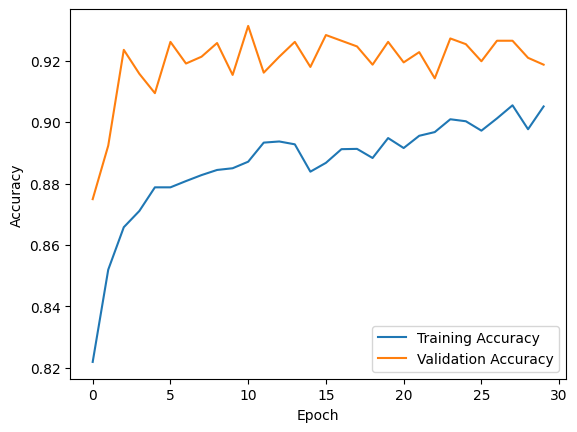

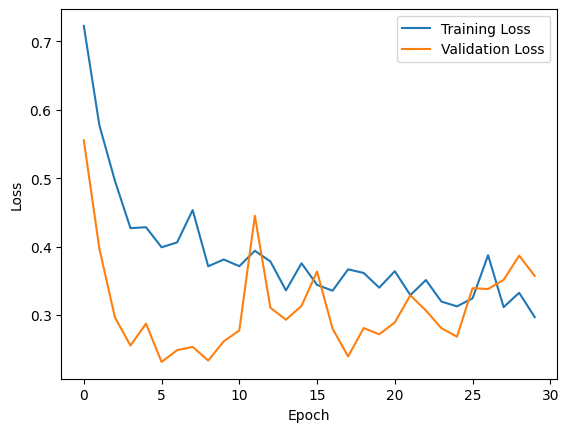

In [11]:
from tensorflow.keras.models import load_model

model.save('vgg16_animals_model.h5')


plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()



In [18]:
import numpy as np
from tensorflow.keras.preprocessing import image

img_path = "/kaggle/input/animals/animals/train/dog/dog1018.jpg"

img = image.load_img(img_path, target_size=img_size)
img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)
predicted_class = np.argmax(prediction[0])
class_names = list(train_generator.class_indices.keys())
print(f"Tahmin: {class_names[predicted_class]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Tahmin: horse
